In [1]:
import kagglehub
path = kagglehub.dataset_download("sachinpatel21/az-handwritten-alphabets-in-csv-format")

Using Colab cache for faster access to the 'az-handwritten-alphabets-in-csv-format' dataset.


In [2]:
import os
os.listdir(path)

['A_Z Handwritten Data.csv', 'A_Z Handwritten Data']

In [3]:
import pandas as pd
df=pd.read_csv(path+'/A_Z Handwritten Data.csv')

In [4]:
df=df.sample(200000)

In [5]:
df.shape

(200000, 785)

In [6]:
df['0'].unique()

array([24, 18, 21, 11, 14, 23, 22,  7, 20, 19,  1, 25,  2,  3,  4,  0, 17,
        6, 13, 15,  9, 12,  5, 10, 16,  8])

In [7]:
y=df['0']
df=df.drop('0',axis=1)

In [8]:
y.dtype

dtype('int64')

In [9]:
import numpy as np
images=np.array(df)

In [10]:
images[0].shape

(784,)

In [11]:
images=images/255

In [12]:
images[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [13]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(images, y, test_size=0.2, random_state=42)
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)

x_train shape: (160000, 28, 28, 1)
x_test shape: (40000, 28, 28, 1)


In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense,Conv2D,MaxPool2D,Dropout,Flatten
from tensorflow.keras.callbacks import EarlyStopping

In [18]:
model = Sequential()
model.add(Input(shape=(28, 28, 1)))
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(26, activation='softmax'))

In [19]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [20]:
model.fit(x_train,y_train,epochs=20,validation_split=0.16,callbacks=[EarlyStopping(patience=5)],batch_size=1000)

Epoch 1/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.7340 - loss: 0.9623 - val_accuracy: 0.9392 - val_loss: 0.2104
Epoch 2/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9370 - loss: 0.2181 - val_accuracy: 0.9651 - val_loss: 0.1218
Epoch 3/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.9581 - loss: 0.1452 - val_accuracy: 0.9709 - val_loss: 0.0999
Epoch 4/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.9663 - loss: 0.1153 - val_accuracy: 0.9765 - val_loss: 0.0854
Epoch 5/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9722 - loss: 0.0967 - val_accuracy: 0.9785 - val_loss: 0.0785
Epoch 6/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9757 - loss: 0.0848 - val_accuracy: 0.9809 - val_loss: 0.0712
Epoch 7/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.9777 - loss: 0.0766 - val_accuracy: 0.9823 - val_loss: 0.0661
Epoch 8/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9794 - loss: 0.0696 - val_acc

In [21]:
model.evaluate(x_test,y_test)

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9880 - loss: 0.0497


[0.049737364053726196, 0.9879500269889832]

In [23]:
from sklearn.metrics import classification_report
y_pred=model.predict(x_test)
y_pred=np.argmax(y_pred,axis=1)
print(classification_report(y_test,y_pred))

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1518
           1       0.99      0.98      0.98       949
           2       0.99      0.99      0.99      2582
           3       0.95      0.97      0.96      1097
           4       0.99      0.99      0.99      1244
           5       0.96      0.97      0.96       118
           6       0.99      0.96      0.98       635
           7       0.99      0.95      0.97       810
           8       1.00      0.97      0.98       125
           9       0.98      0.97      0.98       929
          10       0.97      0.97      0.97       602
          11       0.98      0.99      0.99      1286
          12       0.99      0.99      0.99      1319
          13       0.98      0.99      0.99      2064
          14       0.99      0.99      0.99      6096
          15       0.99      0.99      0.99      2065
          16       0.98      0.98     

In [26]:
pred=model.predict(x_test[0].reshape(1,28,28,1))
pred=np.argmax(pred)
print(pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
17


In [34]:
y_test[:1]

,0
232870,17


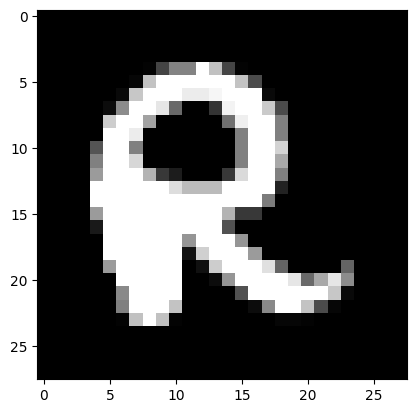

In [35]:
import matplotlib.pyplot as plt
plt.imshow(x_test[0].reshape(28,28),cmap='gray')

In [39]:
import joblib
with open('model.pkl','wb') as f:
    joblib.dump(model,f,compress=3)